In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import AdaBoostClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import linregress

import optuna
from optuna.trial import Trial
from functools import partial

/Users/jimmyzheng0516/anaconda3/envs/python_jimmy/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Question 1

[I 2026-02-23 04:05:23,312] A new study created in memory with name: no-name-24b89998-12cc-41d4-ac07-917a7c72a928
[I 2026-02-23 04:10:00,207] Trial 0 finished with value: -351.623575 and parameters: {'n_estimators': 850}. Best is trial 0 with value: -351.623575.
[I 2026-02-23 04:12:26,920] Trial 1 finished with value: -356.298807 and parameters: {'n_estimators': 450}. Best is trial 0 with value: -351.623575.
[I 2026-02-23 04:17:20,892] Trial 2 finished with value: -347.269603 and parameters: {'n_estimators': 900}. Best is trial 2 with value: -347.269603.
[I 2026-02-23 04:21:41,964] Trial 3 finished with value: -358.185209 and parameters: {'n_estimators': 800}. Best is trial 2 with value: -347.269603.
[I 2026-02-23 04:26:19,106] Trial 4 finished with value: -351.623575 and parameters: {'n_estimators': 850}. Best is trial 2 with value: -347.269603.
[I 2026-02-23 04:28:29,684] Trial 5 finished with value: -353.717087 and parameters: {'n_estimators': 400}. Best is trial 2 with value: -347.

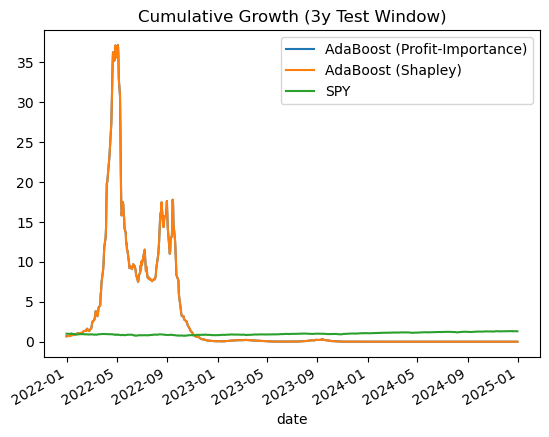

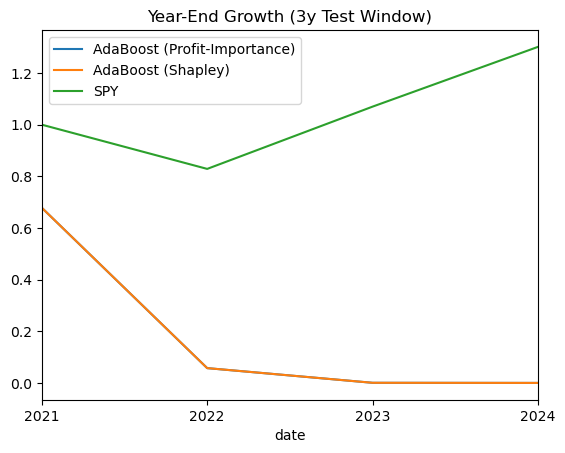

            Strategy  Sharpe (yearly)      Beta     Alpha  \
0  Profit-Importance        -0.658978  1.450309 -0.371626   
1            Shapley        -0.658978  1.450309 -0.371626   

   Max DD (yearly curve)  Final Growth  
0                    1.0  1.388525e-07  
1                    1.0  1.388525e-07  


In [2]:
DATA_PATH = "data_small.pkl"     # change if needed

# Part 1 (single split at end of sample): Train=3y, Test=3y
TRAIN_YEARS = 3
TEST_YEARS  = 3
INTERNAL_VALID_YEARS = 1         # taken from inside the 3y training window (for tuning + feature selection)

N_TRIALS_PROFIT = 30             # maximize sum(pred * next_period_return)

# Part 2 (rolling): Train=3y, Validation=3y; tune to minimize max drawdown on validation
ROLL_TRAIN_YEARS = 3
ROLL_VALID_YEARS = 3
ROLL_STEP_YEARS  = 3
N_TRIALS_DRAWDOWN = 40

RANDOM_STATE = 123


# -----------------------------
# Data prep (from "AdaBoost Strategy")
# -----------------------------
def f(x):
    if x > 0.025:
        return 1
    elif x < -0.025:
        return -1
    else:
        return 0

def load_and_prepare(path: str) -> pd.DataFrame:
    data = pd.read_pickle(path)

    data = data.copy()
    data.replace([np.inf, -np.inf], np.nan, inplace=True)

    # ffill within ticker (same as notebook)
    if isinstance(data.index, pd.MultiIndex) and "ticker" in data.index.names:
        data = data.groupby("ticker").ffill()
    elif "ticker" in data.columns:
        data = data.groupby("ticker").ffill()
    else:
        # best effort if ticker is level=1
        try:
            data = data.groupby(level=1).ffill()
        except Exception:
            pass

    data = data.fillna(0)
    data["rel_performance"] = data["pred_rel_return"].apply(f)

    data = data.reset_index()
    if "date" not in data.columns:
        raise ValueError("No 'date' column found after reset_index().")
    data["date"] = pd.to_datetime(data["date"])
    data = data.set_index("date").sort_index()
    return data

def get_feature_cols(df: pd.DataFrame) -> list[str]:
    drop_cols = [
        "ticker", "date",
        "next_period_return", "spy_next_period_return",
        "rel_performance", "pred_rel_return",
        "return", "cum_ret", "spy_cum_ret",
    ]
    return [c for c in df.columns if c not in drop_cols]

def slice_open(df: pd.DataFrame, start, end) -> pd.DataFrame:
    start = pd.to_datetime(start)
    end = pd.to_datetime(end)
    return df[(df.index >= start) & (df.index < end)]

def get_spy_cum(df_period: pd.DataFrame) -> pd.Series:
    if "spy_cum_ret" in df_period.columns:
        spy = df_period.groupby(df_period.index)["spy_cum_ret"].first()
        return spy - spy.iloc[0] + 1
    if "spy_next_period_return" in df_period.columns:
        spy_ret = df_period.groupby(df_period.index)["spy_next_period_return"].first()
        return (1 + spy_ret).cumprod()
    raise ValueError("Need spy_cum_ret or spy_next_period_return in the data.")

def yearly_curve(cum: pd.Series) -> pd.Series:
    return cum.sort_index().resample("YE").ffill()

def sharpe_yearly(cum: pd.Series) -> float:
    y = yearly_curve(cum)
    r = (y - 1).diff().dropna()
    if r.std() == 0:
        return np.nan
    return float(r.mean() / r.std())

def beta_alpha_yearly(strategy_cum: pd.Series, spy_cum: pd.Series) -> tuple[float, float]:
    ys = yearly_curve(strategy_cum)
    yb = yearly_curve(spy_cum)
    rs = (ys - 1).diff().dropna()
    rb = (yb - 1).diff().dropna()
    idx = rs.index.intersection(rb.index)
    if len(idx) < 2:
        return np.nan, np.nan
    res = linregress(rb.loc[idx].values, rs.loc[idx].values)
    return float(res.slope), float(res.intercept)

def max_drawdown_from_cum(cum: pd.Series) -> float:
    cum = cum.sort_index()
    roll_max = cum.cummax()
    dd = (cum / roll_max) - 1.0
    return float((-dd.min()))  # positive

def portfolio_returns_by_date(model, X: pd.DataFrame, df_period: pd.DataFrame) -> pd.Series:
    preds = model.predict(X)
    tmp = df_period[["next_period_return"]].copy()
    tmp["pred"] = preds

    def _one_date(g):
        p = g["pred"].values
        r = g["next_period_return"].values
        denom = np.abs(p).sum()
        if denom == 0:
            return 0.0
        return float((p * r).sum() / denom)

    return tmp.groupby(tmp.index).apply(_one_date).sort_index()

def cum_from_returns(ret: pd.Series, start_value: float = 1.0) -> pd.Series:
    return start_value * (1.0 + ret.fillna(0.0)).cumprod()


# -----------------------------
# Profit Importance + SHAP (from "AdaBoost Strategy", adapted)
# -----------------------------
def ada_boost_feat_importance(m, df: pd.DataFrame) -> pd.DataFrame:
    feature_importances = []
    for est in m.estimators_:
        feature_importances.append(est.feature_importances_)
    feature_importances = np.array(feature_importances)
    return pd.DataFrame(
        {"cols": df.columns, "feat_imp": np.mean(feature_importances, axis=0)}
    ).sort_values("feat_imp", ascending=False)

def profit_importance(t, df: pd.DataFrame, rets: np.ndarray) -> list[float]:
    profit = []
    for col in df.columns:
        X = df.copy()
        X[col] = np.random.permutation(df[col].values)
        prediction = t.predict(X)
        profit.append((prediction * rets).sum())
    return profit

def adaboost_profit_importance(m, df: pd.DataFrame, rets: np.ndarray) -> pd.DataFrame:
    return pd.DataFrame(
        {"cols": df.columns, "pi_imp": profit_importance(m, df, rets)}
    ).sort_values("pi_imp", ascending=True)

def objective_profit(trial: Trial, train=None, labels=None, val=None, val_rets=None):
    t_n_estimators = trial.suggest_int("n_estimators", 50, 1200, step=50)
    ada_clf = AdaBoostClassifier(n_estimators=t_n_estimators, random_state=RANDOM_STATE)
    ada_clf.fit(train, labels)
    preds = ada_clf.predict(val)
    profit = (preds * val_rets).sum()
    return profit

def tune_profit_params(X_train, y_train, X_val, val_rets, n_trials=N_TRIALS_PROFIT) -> dict:
    obj = partial(objective_profit, train=X_train, labels=y_train, val=X_val, val_rets=val_rets)
    study = optuna.create_study(direction="maximize")
    study.optimize(obj, n_trials=n_trials, show_progress_bar=False)
    return dict(study.best_params)

def profit_importance_feature_selection(base_model, X_train: pd.DataFrame, y_train: np.ndarray,
                                      X_val: pd.DataFrame, val_rets: np.ndarray) -> list[str]:
    # fit on full set to get non-zero feature importances
    base_model.fit(X_train, y_train)
    fi = ada_boost_feat_importance(base_model, X_train)
    cols = fi.loc[fi["feat_imp"] > 0.0, "cols"].tolist()
    if len(cols) < 2:
        cols = X_train.columns.tolist()

    train_red = X_train[cols].copy()
    valid_red = X_val[cols].copy()

    # IMPORTANT: refit on the reduced column set so predict() sees the same feature names
    base_model.fit(train_red, y_train)
    pi = adaboost_profit_importance(base_model, valid_red, val_rets)

    profits = []
    feats = []

    train = train_red.copy()
    validation = valid_red.copy()

    while len(train.columns) > 1:
        col_to_drop = pi.iloc[-1]["cols"]
        train.drop(col_to_drop, axis=1, inplace=True)
        validation.drop(col_to_drop, axis=1, inplace=True)

        base_model.fit(train, y_train)
        pi = adaboost_profit_importance(base_model, validation, val_rets)

        pred_valid = base_model.predict(validation)
        prof = (pred_valid * val_rets).sum()
        profits.append(prof)
        feats.append(train.columns.tolist())

    if len(profits) == 0:
        return cols

    best_idx = int(np.argmax(profits))
    return feats[best_idx]

def shapley_feature_selection(model, X_val: pd.DataFrame, max_evals: int = 2000) -> list[str]:
    try:
        import shap
        explainer = shap.Explainer(model, X_val)
        shap_values = explainer(X_val, max_evals=max_evals)
        shap_summary = np.abs(np.stack(shap_values.values)).mean(axis=0)
        shap_df = pd.DataFrame({"Feature": X_val.columns, "MeanAbsSHAP": shap_summary})
        shap_df = shap_df.sort_values("MeanAbsSHAP", ascending=False)
        return shap_df.loc[shap_df["MeanAbsSHAP"] > 0, "Feature"].tolist()
    except Exception:
        return X_val.columns.tolist()


# -----------------------------
# Part 1: Train=3y, Test=3y. Use internal (last 1y of train) as validation.
# -----------------------------
data = load_and_prepare(DATA_PATH)
feat_cols = get_feature_cols(data)

last_date = data.index.max()
test_start = last_date - pd.DateOffset(years=TEST_YEARS)
train_start = test_start - pd.DateOffset(years=TRAIN_YEARS)

df_train = slice_open(data, train_start, test_start)
df_test  = slice_open(data, test_start, last_date + pd.Timedelta(days=1))

# internal validation inside training window
val_start = test_start - pd.DateOffset(years=INTERNAL_VALID_YEARS)
df_subtrain = slice_open(data, train_start, val_start)
df_valid_in = slice_open(data, val_start, test_start)

X_train_full = df_train[feat_cols].copy()
X_subtrain   = df_subtrain[feat_cols].copy()
X_valid_in   = df_valid_in[feat_cols].copy()
X_test       = df_test[feat_cols].copy()

y_subtrain   = df_subtrain["rel_performance"].values
y_valid_in   = df_valid_in["rel_performance"].values
y_train_full = df_train["rel_performance"].values

val_rets = df_valid_in["next_period_return"].values

# scale float columns (fit on full training)
float_vars = [c for c in X_train_full.columns if X_train_full[c].dtype == "float64"]
scaler = MinMaxScaler()
X_train_full[float_vars] = scaler.fit_transform(X_train_full[float_vars])
X_subtrain[float_vars]   = scaler.transform(X_subtrain[float_vars])
X_valid_in[float_vars]   = scaler.transform(X_valid_in[float_vars])
X_test[float_vars]       = scaler.transform(X_test[float_vars])

# ---- Profit Importance params + features ----
pi_params = tune_profit_params(X_subtrain, y_subtrain, X_valid_in, val_rets)
pi_base = AdaBoostClassifier(**pi_params, random_state=RANDOM_STATE)

pi_feats = profit_importance_feature_selection(pi_base, X_subtrain, y_subtrain, X_valid_in, val_rets)

X_sub_pi  = X_subtrain[pi_feats].copy()
X_val_pi  = X_valid_in[pi_feats].copy()
X_full_pi = X_train_full[pi_feats].copy()
X_test_pi = X_test[pi_feats].copy()

pi_params2 = tune_profit_params(X_sub_pi, y_subtrain, X_val_pi, val_rets)
pi_model = AdaBoostClassifier(**pi_params2, random_state=RANDOM_STATE)
pi_model.fit(X_full_pi, y_train_full)

pi_ret = portfolio_returns_by_date(pi_model, X_test_pi, df_test)
pi_cum = cum_from_returns(pi_ret)

# ---- Shapley params + features ----
sh_base = AdaBoostClassifier(**pi_params2, random_state=RANDOM_STATE)
sh_base.fit(X_full_pi, y_train_full)

sh_feats = shapley_feature_selection(sh_base, X_val_pi)
if len(sh_feats) < 2:
    sh_feats = pi_feats

X_sub_sh  = X_subtrain[sh_feats].copy()
X_val_sh  = X_valid_in[sh_feats].copy()
X_full_sh = X_train_full[sh_feats].copy()
X_test_sh = X_test[sh_feats].copy()

sh_params = tune_profit_params(X_sub_sh, y_subtrain, X_val_sh, val_rets)
sh_model = AdaBoostClassifier(**sh_params, random_state=RANDOM_STATE)
sh_model.fit(X_full_sh, y_train_full)

sh_ret = portfolio_returns_by_date(sh_model, X_test_sh, df_test)
sh_cum = cum_from_returns(sh_ret)

spy_cum = get_spy_cum(df_test)

# ---- Graphs (submit) ----
plt.figure()
pi_cum.plot(label="AdaBoost (Profit-Importance)")
sh_cum.plot(label="AdaBoost (Shapley)")
spy_cum.plot(label="SPY")
plt.title("Cumulative Growth (3y Test Window)")
plt.legend()
plt.show()

plt.figure()
yearly_curve(pi_cum).plot(label="AdaBoost (Profit-Importance)")
yearly_curve(sh_cum).plot(label="AdaBoost (Shapley)")
yearly_curve(spy_cum).plot(label="SPY")
plt.title("Year-End Growth (3y Test Window)")
plt.legend()
plt.show()

# ---- Metrics (submit) ----
rows = []
for name, strat in [("Profit-Importance", pi_cum), ("Shapley", sh_cum)]:
    sr = sharpe_yearly(strat)
    beta, alpha = beta_alpha_yearly(strat, spy_cum)
    mdd = max_drawdown_from_cum(yearly_curve(strat))
    rows.append([name, sr, beta, alpha, mdd, float(strat.iloc[-1])])

metrics_df = pd.DataFrame(
    rows,
    columns=["Strategy", "Sharpe (yearly)", "Beta", "Alpha", "Max DD (yearly curve)", "Final Growth"],
)
print(metrics_df)


#### Question 2

[I 2026-02-23 09:34:23,260] A new study created in memory with name: no-name-5a977020-2cd7-4050-bc65-e201829a9571
/Users/jimmyzheng0516/anaconda3/envs/python_jimmy/lib/python3.11/site-packages/optuna/distributions.py:684: UserWarning: The distribution is specified by [1, 50] and step=5, but the range is not divisible by `step`. It will be replaced with [1, 46].
  optuna_warn(
[I 2026-02-23 09:42:32,850] Trial 0 finished with value: 10.036691423082758 and parameters: {'n_estimators': 650, 'learning_rate': 0.01078616650504967, 'max_depth': 3, 'min_samples_leaf': 21}. Best is trial 0 with value: 10.036691423082758.
/Users/jimmyzheng0516/anaconda3/envs/python_jimmy/lib/python3.11/site-packages/optuna/distributions.py:684: UserWarning: The distribution is specified by [1, 50] and step=5, but the range is not divisible by `step`. It will be replaced with [1, 46].
  optuna_warn(
[I 2026-02-23 09:50:41,726] Trial 1 finished with value: 49.557575435439134 and parameters: {'n_estimators': 950, '

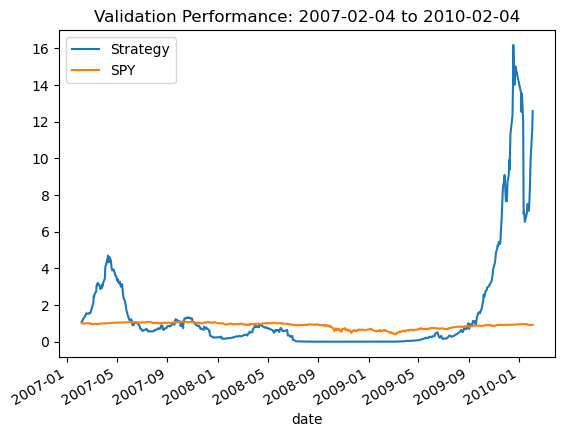

[I 2026-02-23 12:59:17,228] A new study created in memory with name: no-name-18915f17-1b46-4556-9be8-908e0cf9981b
/Users/jimmyzheng0516/anaconda3/envs/python_jimmy/lib/python3.11/site-packages/optuna/distributions.py:684: UserWarning: The distribution is specified by [1, 50] and step=5, but the range is not divisible by `step`. It will be replaced with [1, 46].
  optuna_warn(
[I 2026-02-23 13:00:21,358] Trial 0 finished with value: -0.0 and parameters: {'n_estimators': 200, 'learning_rate': 0.7249431373592826, 'max_depth': 1, 'min_samples_leaf': 6}. Best is trial 0 with value: -0.0.
/Users/jimmyzheng0516/anaconda3/envs/python_jimmy/lib/python3.11/site-packages/optuna/distributions.py:684: UserWarning: The distribution is specified by [1, 50] and step=5, but the range is not divisible by `step`. It will be replaced with [1, 46].
  optuna_warn(
[I 2026-02-23 13:01:06,105] Trial 1 finished with value: -0.0 and parameters: {'n_estimators': 50, 'learning_rate': 0.1838864217668703, 'max_dept

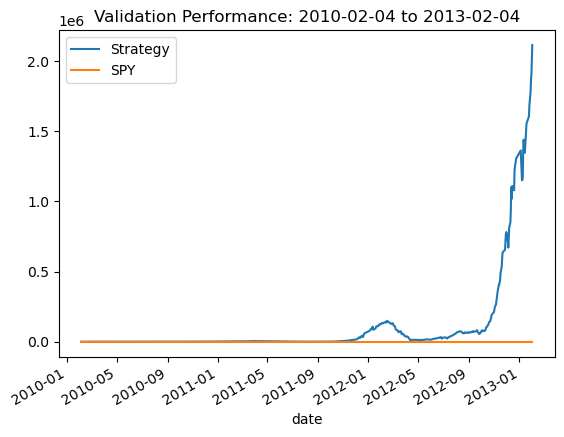

[I 2026-02-23 15:05:24,538] A new study created in memory with name: no-name-831397bc-576d-4999-ac57-504f09e661ff
/Users/jimmyzheng0516/anaconda3/envs/python_jimmy/lib/python3.11/site-packages/optuna/distributions.py:684: UserWarning: The distribution is specified by [1, 50] and step=5, but the range is not divisible by `step`. It will be replaced with [1, 46].
  optuna_warn(
[I 2026-02-23 15:06:35,089] Trial 0 finished with value: 0.5285807800207212 and parameters: {'n_estimators': 100, 'learning_rate': 0.5276796118572014, 'max_depth': 2, 'min_samples_leaf': 11}. Best is trial 0 with value: 0.5285807800207212.
/Users/jimmyzheng0516/anaconda3/envs/python_jimmy/lib/python3.11/site-packages/optuna/distributions.py:684: UserWarning: The distribution is specified by [1, 50] and step=5, but the range is not divisible by `step`. It will be replaced with [1, 46].
  optuna_warn(
[I 2026-02-23 15:22:05,339] Trial 1 finished with value: 0.8908632874744592 and parameters: {'n_estimators': 900, 'l

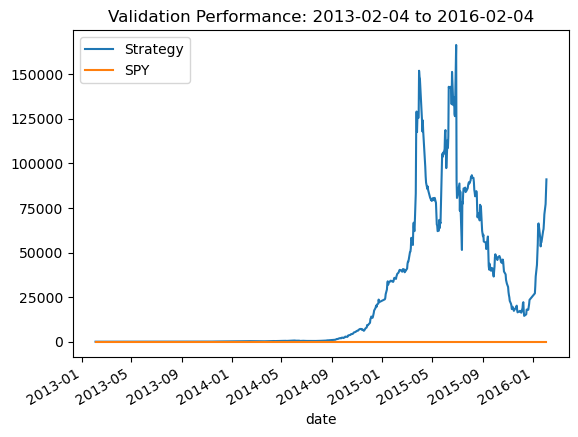

[I 2026-02-23 19:05:12,648] A new study created in memory with name: no-name-74f407dc-ac1e-4569-afa0-d49dd1e1da37
/Users/jimmyzheng0516/anaconda3/envs/python_jimmy/lib/python3.11/site-packages/optuna/distributions.py:684: UserWarning: The distribution is specified by [1, 50] and step=5, but the range is not divisible by `step`. It will be replaced with [1, 46].
  optuna_warn(
[I 2026-02-23 19:15:47,962] Trial 0 finished with value: -0.0 and parameters: {'n_estimators': 700, 'learning_rate': 0.015656876217530296, 'max_depth': 2, 'min_samples_leaf': 36}. Best is trial 0 with value: -0.0.
/Users/jimmyzheng0516/anaconda3/envs/python_jimmy/lib/python3.11/site-packages/optuna/distributions.py:684: UserWarning: The distribution is specified by [1, 50] and step=5, but the range is not divisible by `step`. It will be replaced with [1, 46].
  optuna_warn(
[I 2026-02-23 19:17:00,468] Trial 1 finished with value: 0.21892952227374385 and parameters: {'n_estimators': 150, 'learning_rate': 0.03328403

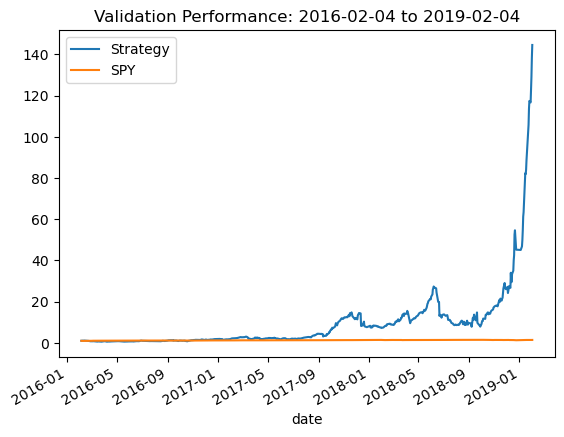

[I 2026-02-24 02:02:30,460] A new study created in memory with name: no-name-37722bb4-a15b-4e14-bd00-c1e7ec2a94c8
/Users/jimmyzheng0516/anaconda3/envs/python_jimmy/lib/python3.11/site-packages/optuna/distributions.py:684: UserWarning: The distribution is specified by [1, 50] and step=5, but the range is not divisible by `step`. It will be replaced with [1, 46].
  optuna_warn(
[I 2026-02-24 02:21:02,460] Trial 0 finished with value: 1.000016432653727 and parameters: {'n_estimators': 1200, 'learning_rate': 0.014204319728693064, 'max_depth': 2, 'min_samples_leaf': 41}. Best is trial 0 with value: 1.000016432653727.
/Users/jimmyzheng0516/anaconda3/envs/python_jimmy/lib/python3.11/site-packages/optuna/distributions.py:684: UserWarning: The distribution is specified by [1, 50] and step=5, but the range is not divisible by `step`. It will be replaced with [1, 46].
  optuna_warn(
[I 2026-02-24 02:38:02,925] Trial 1 finished with value: 1.0001646088012004 and parameters: {'n_estimators': 1100, 

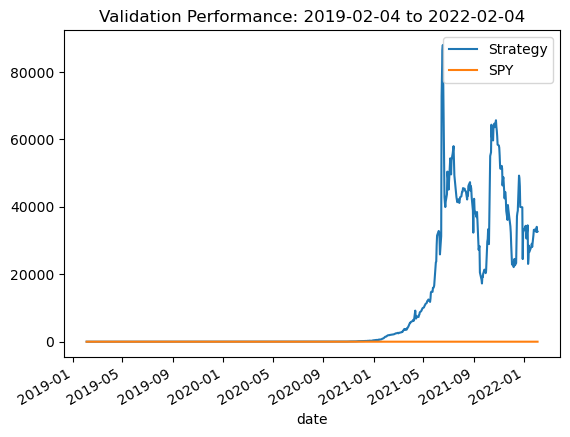

  train_start   train_end valid_start   valid_end  Sharpe (yearly)  \
0  2004-02-04  2007-02-04  2007-02-04  2010-02-04         0.432761   
1  2007-02-04  2010-02-04  2010-02-04  2013-02-04         1.173306   
2  2010-02-04  2013-02-04  2013-02-04  2016-02-04         0.893587   
3  2013-02-04  2016-02-04  2016-02-04  2019-02-04         1.000240   
4  2016-02-04  2019-02-04  2019-02-04  2022-02-04         0.595235   

           Beta         Alpha  Max DD (yearly curve)  Final Growth  \
0  2.146967e+01      5.103152               0.998204  1.257498e+01   
1  8.440395e+06 -36229.393173              -0.000000  2.116200e+06   
2 -1.941209e+05  36482.269727              -0.000000  9.103063e+04   
3  1.035983e+01     46.772250              -0.000000  1.445950e+02   
4  6.303240e+04   1928.334814              -0.000000  3.266208e+04   

   best_n_estimators  best_learning_rate  best_max_depth  \
0                400            0.974266               3   
1                200            0.7249

In [3]:

# -----------------------------
# Part 2: rolling hyperparams minimizing max drawdown on validation
# -----------------------------
def build_adaboost_from_trial(trial: Trial):
    n_estimators  = trial.suggest_int("n_estimators", 50, 1200, step=50)
    learning_rate = trial.suggest_float("learning_rate", 0.01, 1.0, log=True)
    max_depth     = trial.suggest_int("max_depth", 1, 3)
    min_leaf      = trial.suggest_int("min_samples_leaf", 1, 50, step=5)

    stump = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_leaf=min_leaf,
        random_state=RANDOM_STATE,
    )
    try:
        clf = AdaBoostClassifier(
            estimator=stump,
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            random_state=RANDOM_STATE,
        )
    except TypeError:
        clf = AdaBoostClassifier(
            base_estimator=stump,
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            random_state=RANDOM_STATE,
        )
    return clf

def objective_drawdown(trial: Trial, X_tr, y_tr, X_val, df_val):
    clf = build_adaboost_from_trial(trial)
    clf.fit(X_tr, y_tr)
    ret = portfolio_returns_by_date(clf, X_val, df_val)
    cum = cum_from_returns(ret)
    mdd = max_drawdown_from_cum(yearly_curve(cum))
    return mdd

def rolling_windows(df: pd.DataFrame, train_years: int, valid_years: int, step_years: int):
    start = df.index.min()
    end = df.index.max()

    out = []
    cur = start
    while True:
        tr_start = cur
        tr_end   = tr_start + pd.DateOffset(years=train_years)
        va_start = tr_end
        va_end   = va_start + pd.DateOffset(years=valid_years)

        if va_end > end:
            break

        out.append((tr_start, tr_end, va_start, va_end))
        cur = cur + pd.DateOffset(years=step_years)

    return out

roll_rows = []
wins = rolling_windows(data, ROLL_TRAIN_YEARS, ROLL_VALID_YEARS, ROLL_STEP_YEARS)

for (tr_start, tr_end, va_start, va_end) in wins:
    df_tr = slice_open(data, tr_start, tr_end)
    df_va = slice_open(data, va_start, va_end)

    y_tr = df_tr["rel_performance"].values
    X_tr = df_tr[feat_cols].copy()
    X_va = df_va[feat_cols].copy()

    float_vars = [c for c in X_tr.columns if X_tr[c].dtype == "float64"]
    sc = MinMaxScaler()
    X_tr[float_vars] = sc.fit_transform(X_tr[float_vars])
    X_va[float_vars] = sc.transform(X_va[float_vars])

    obj = partial(objective_drawdown, X_tr=X_tr, y_tr=y_tr, X_val=X_va, df_val=df_va)
    study = optuna.create_study(direction="minimize")
    study.optimize(obj, n_trials=N_TRIALS_DRAWDOWN, show_progress_bar=False)

    best = study.best_params

    stump = DecisionTreeClassifier(
        max_depth=int(best["max_depth"]),
        min_samples_leaf=int(best["min_samples_leaf"]),
        random_state=RANDOM_STATE,
    )
    try:
        clf = AdaBoostClassifier(
            estimator=stump,
            n_estimators=int(best["n_estimators"]),
            learning_rate=float(best["learning_rate"]),
            random_state=RANDOM_STATE,
        )
    except TypeError:
        clf = AdaBoostClassifier(
            base_estimator=stump,
            n_estimators=int(best["n_estimators"]),
            learning_rate=float(best["learning_rate"]),
            random_state=RANDOM_STATE,
        )

    clf.fit(X_tr, y_tr)

    va_ret = portfolio_returns_by_date(clf, X_va, df_va)
    va_cum = cum_from_returns(va_ret)
    spy_cum_va = get_spy_cum(df_va)

    b, a = beta_alpha_yearly(va_cum, spy_cum_va)

    roll_rows.append({
        "train_start": tr_start.date(),
        "train_end": tr_end.date(),
        "valid_start": va_start.date(),
        "valid_end": va_end.date(),
        "Sharpe (yearly)": sharpe_yearly(va_cum),
        "Beta": b,
        "Alpha": a,
        "Max DD (yearly curve)": max_drawdown_from_cum(yearly_curve(va_cum)),
        "Final Growth": float(va_cum.iloc[-1]),
        **{f"best_{k}": v for k, v in best.items()},
    })

    plt.figure()
    va_cum.plot(label="Strategy")
    spy_cum_va.plot(label="SPY")
    plt.title(f"Validation Performance: {va_start.date()} to {va_end.date()}")
    plt.legend()
    plt.show()

roll_df = pd.DataFrame(roll_rows)
print(roll_df)